# IMDB Sentiment Analysis


**Pipeline:** load the dataset and import the libraries -> clean text -> stratified train/val/test split -> compare two models
(average-pooling baseline vs. Bidirectional LSTM) on the *validation* set -> evaluate the winner on the *test* set once -> save and reload for inference.

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import tensorflow as tf
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

for pkg in ["stopwords", "wordnet"]:
    nltk.download(pkg, quiet=True)

# Reproducibility: fixes Python, NumPy and TensorFlow seeds
SEED = 42
tf.keras.utils.set_random_seed(SEED)


DATA_PATH = "IMDB Dataset.csv.zip"
VOCAB_SIZE = 20_000
MAX_LEN = 200
EMBED_DIM = 64
BATCH_SIZE = 64
EPOCHS = 10

 **Load data**
Duplicates are dropped so the same review can't appear in both train and test.

In [ ]:
df = pd.read_csv('IMDB Dataset.csv.zip').dropna().drop_duplicates().reset_index(drop=True)
df["label"] = (df["sentiment"] == "positive").astype(int)

print(df.shape)
print(df["label"].value_counts())
df.head()

(49582, 3)
label
1    24884
0    24698
Name: count, dtype: int64


,review,sentiment,label
0,One of the other reviewers has mentioned that ...,positive,1
1,A wonderful little production. <br /><br />The...,positive,1
2,I thought this was a wonderful way to spend ti...,positive,1
3,Basically there's a family where a little boy ...,negative,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1


 Text cleaning


In [ ]:
NEGATIONS = {"no", "nor", "not"} | {w for w in stopwords.words("english") if w.endswith("n't")}
STOPWORDS = set(stopwords.words("english")) - NEGATIONS
lemmatizer = WordNetLemmatizer()

def clean_text(text: str) -> str:
    text = re.sub(r"<[^>]+>", " ", text)          # remove HTML tags
    text = re.sub(r"[^a-z' ]", " ", text.lower())  # keep letters and apostrophes
    tokens = [t.strip("'") for t in text.split()]
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t and t not in STOPWORDS]
    return " ".join(tokens)

print(clean_text("This movie was <br />NOT good, I didn't like the acting!"))
df["clean"] = df["review"].apply(clean_text)
print("Average tokens per review:", df["clean"].str.split().str.len().mean().round(1))

movie not good didn't like acting
Average tokens per review: 121.7


Train / validation / test split (60 / 20 / 20, stratified)

In [ ]:
X_train, X_tmp, y_train, y_tmp = train_test_split(
    df["clean"], df["label"], test_size=0.4, stratify=df["label"], random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)

print(len(X_train), len(X_val), len(X_test))

def make_ds(X, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X.tolist(), y.values.astype("float32")))
    if shuffle:
        ds = ds.shuffle(10_000, seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train, y_train, shuffle=True)
val_ds = make_ds(X_val, y_val)
test_ds = make_ds(X_test, y_test)

29749 9916 9917


 Vectorization
The vocabulary is learned from the **training set only** and built into the model, so the saved model accepts raw (cleaned) strings.

In [ ]:
vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=VOCAB_SIZE, output_mode="int", output_sequence_length=MAX_LEN)
vectorizer.adapt(X_train.tolist())
print(vectorizer.get_vocabulary()[:20])

['', '[UNK]', np.str_('movie'), np.str_('film'), np.str_('not'), np.str_('one'), np.str_('like'), np.str_('time'), np.str_('good'), np.str_('character'), np.str_('no'), np.str_('story'), np.str_('even'), np.str_('would'), np.str_('get'), np.str_('make'), np.str_('see'), np.str_('really'), np.str_('scene'), np.str_('well')]


 Models
Two architectures are compared. Both use dropout, L2 regularization and early stopping to reduce the overfitting seen in the first version (train ~96% vs. val ~88%).

In [ ]:
def build_model(kind: str) -> tf.keras.Model:
    inputs = tf.keras.Input(shape=(), dtype=tf.string)
    x = vectorizer(inputs)
    x = tf.keras.layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=(kind == "bilstm"))(x)
    if kind == "bilstm":
        x = tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, dropout=0.3))(x)
    else:
        x = tf.keras.layers.GlobalAveragePooling1D()(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    x = tf.keras.layers.Dense(32, activation="relu",
                              kernel_regularizer=tf.keras.regularizers.l2(1e-3))(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    model = tf.keras.Model(inputs, outputs, name=f"imdb_{kind}")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

def make_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1),
    ]

build_model("bilstm").summary()

Model: "imdb_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 200)       │          0 │ input_layer[0][0] │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 200, 64)   │  1,280,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 200)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 64)        │     24,832 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      2,080 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         33 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,306,945 (4.99 MB)

 Trainable params: 1,306,945 (4.99 MB)

 Non-trainable params: 0 (0.00 B)

 Train and compare on the validation set

In [ ]:
models, histories, val_scores = {}, {}, {}

for kind in ["pooling", "bilstm"]:
    print(f"\n=== Training {kind} ===")
    model = build_model(kind)
    histories[kind] = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                                callbacks=make_callbacks(), verbose=2)
    models[kind] = model
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    val_scores[kind] = {"val_loss": round(val_loss, 4), "val_accuracy": round(val_acc, 4)}

pd.DataFrame(val_scores).T


=== Training pooling ===
Epoch 1/10
465/465 - 12s - 27ms/step - accuracy: 0.6681 - loss: 0.6380 - val_accuracy: 0.8236 - val_loss: 0.4595 - learning_rate: 0.0010
Epoch 2/10
465/465 - 10s - 22ms/step - accuracy: 0.8493 - loss: 0.4031 - val_accuracy: 0.8785 - val_loss: 0.3473 - learning_rate: 0.0010
Epoch 3/10
465/465 - 11s - 23ms/step - accuracy: 0.8830 - loss: 0.3275 - val_accuracy: 0.8774 - val_loss: 0.3290 - learning_rate: 0.0010
Epoch 4/10
465/465 - 12s - 25ms/step - accuracy: 0.8989 - loss: 0.2895 - val_accuracy: 0.8868 - val_loss: 0.3088 - learning_rate: 0.0010
Epoch 5/10
465/465 - 10s - 23ms/step - accuracy: 0.9084 - loss: 0.2683 - val_accuracy: 0.8687 - val_loss: 0.3297 - learning_rate: 0.0010
Epoch 6/10
465/465 - 10s - 22ms/step - accuracy: 0.9259 - loss: 0.2330 - val_accuracy: 0.8896 - val_loss: 0.3016 - learning_rate: 5.0000e-04
Epoch 7/10
465/465 - 20s - 44ms/step - accuracy: 0.9324 - loss: 0.2201 - val_accuracy: 0.8926 - val_loss: 0.2981 - learning_rate: 5.0000e-04
Epoch 8

,val_loss,val_accuracy
pooling,0.2981,0.8908
bilstm,0.2895,0.8848


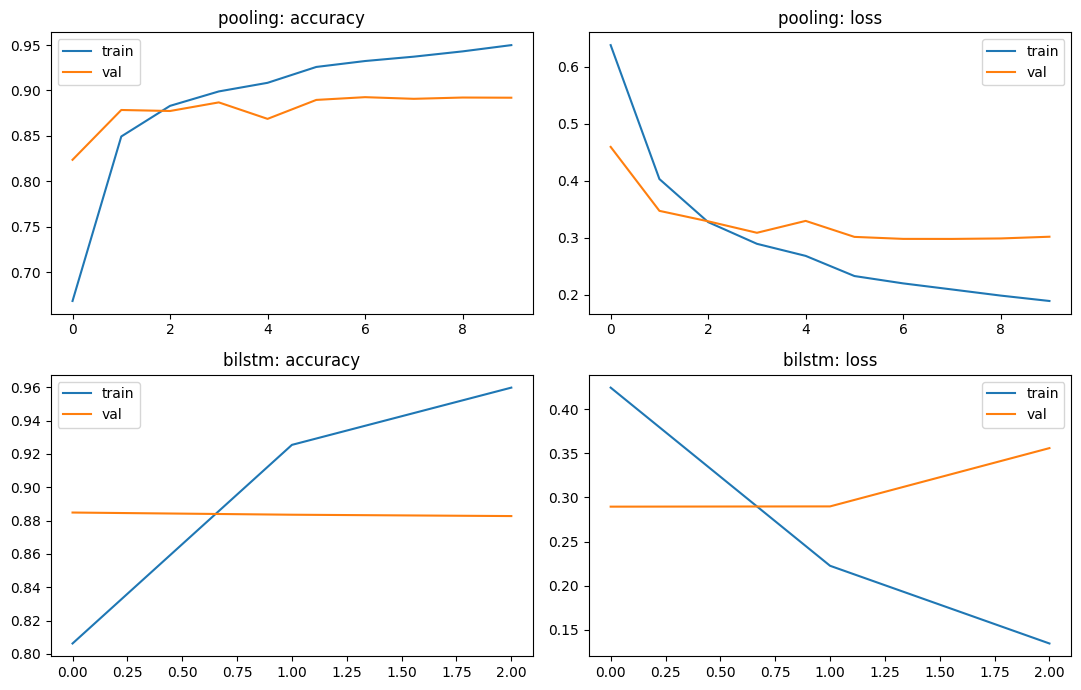

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, kind in enumerate(histories):
    h = histories[kind].history
    axes[row, 0].plot(h["accuracy"], label="train"); axes[row, 0].plot(h["val_accuracy"], label="val")
    axes[row, 0].set_title(f"{kind}: accuracy"); axes[row, 0].legend()
    axes[row, 1].plot(h["loss"], label="train"); axes[row, 1].plot(h["val_loss"], label="val")
    axes[row, 1].set_title(f"{kind}: loss"); axes[row, 1].legend()
plt.tight_layout(); plt.show()

 Final evaluation on the test set (used once)

Selected model: pooling
              precision    recall  f1-score   support

    negative       0.89      0.90      0.89      4940
    positive       0.90      0.89      0.89      4977

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89      0.89      9917



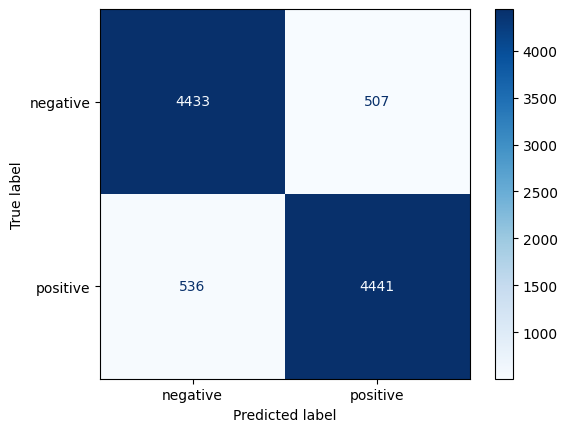

In [ ]:
best_kind = max(val_scores, key=lambda k: val_scores[k]["val_accuracy"])
best_model = models[best_kind]
print("Selected model:", best_kind)

probs = best_model.predict(test_ds, verbose=0).ravel()
preds = (probs > 0.5).astype(int)
y_true = y_test.values

print(classification_report(y_true, preds, target_names=["negative", "positive"]))
ConfusionMatrixDisplay(confusion_matrix(y_true, preds),
                       display_labels=["negative", "positive"]).plot(cmap="Blues")
plt.show()

 Error analysis
Look at the most confident mistakes to see what the model struggles with (sarcasm, mixed reviews, ...).

In [ ]:
errors = X_test.to_frame("clean").assign(true=y_true, prob=probs, pred=preds)
errors = errors[errors["true"] != errors["pred"]].copy()
errors["confidence"] = np.where(errors["pred"] == 1, errors["prob"], 1 - errors["prob"])

for _, r in errors.sort_values("confidence", ascending=False).head(5).iterrows():
    print(f"true={r['true']} pred={r['pred']} conf={r['confidence']:.2f}")
    print(r["clean"][:300], "...\n")

true=1 pred=0 conf=1.00
spoiler ahead really unfortunate movie well produced turn disappointment thought full silly clich basically tried hard american guy many spend time jumping girlfriend's bed making monkey sound married girl many suddenly gone prude nympho overnight not husband french would really ask someone la fac k ...

true=1 pred=0 conf=1.00
basically endearingly chintzy moronic version nifty early subterranean creature feature favorite boogens entertainingly schlocky cheapie center nasty squirmy wriggling monster make instant meal unfortunate soul foolhardy enough go poking around notoriously limit gold spike mine standard issue motley ...

true=0 pred=1 conf=1.00
brave one new york radio show host named erica bain jodie foster life dream living city grew love great fianc david naveen andrew planning marry one night erica david walking dog attacked mugged group degenerate leaving david dead erica recovers heartbroken traumatized later barely cope real life an ...

true=1 pre

 Save the model and run inference
The vectorizer is part of the model, so only the cleaning function is needed at inference time.

In [ ]:
best_model.save("model.keras")
loaded = tf.keras.models.load_model("model.keras")

def predict_sentiment(texts, model=loaded):
    if isinstance(texts, str):
        texts = [texts]
    cleaned = tf.constant([clean_text(t) for t in texts])
    scores = model.predict(cleaned, verbose=0).ravel()
    return [{"text": t, "sentiment": "positive" if s > 0.5 else "negative",
             "score": round(float(s), 3)} for t, s in zip(texts, scores)]

predict_sentiment([
    "The cinematography was creative. I suggest this movie.",
    "It was full of thrill but contains unnecessary drama.",
    "Not good at all, a complete waste of time.",
])

[{'text': 'The cinematography was creative. I suggest this movie.',
  'sentiment': 'positive',
  'score': 0.504},
 {'text': 'It was full of thrill but contains unnecessary drama.',
  'sentiment': 'negative',
  'score': 0.498},
 {'text': 'Not good at all, a complete waste of time.',
  'sentiment': 'negative',
  'score': 0.134}]